# 01 — Análise Exploratória (EDA)

**Objetivo:** levantar hipóteses que orientem feature engineering, imputação e escolha de técnicas (escala, balanceamento).
Cada seção termina com uma decisão de modelagem.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from titanic.config import FIGURES_DIR, TARGET
from titanic.data import load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

train, test = load_raw()
full = pd.concat([train.assign(dataset="train"), test.assign(dataset="test")], ignore_index=True)


def survival_table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Taxa de sobrevivência e tamanho de cada grupo de `col`."""
    return (
        df.groupby(col, observed=True)[TARGET]
        .agg(taxa="mean", n="size")
        .round(3)
        .sort_values("taxa", ascending=False)
    )


def save_fig(fig: plt.Figure, name: str) -> None:
    """Salva a figura em reports/figures."""
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


print(train.shape, test.shape, full.shape)

(891, 12) (418, 11) (1309, 13)


In [2]:
train.info()
train.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
missing = pd.DataFrame(
    {
        "train_pct": train.isna().mean().mul(100).round(1),
        "test_pct": test.isna().mean().mul(100).round(1),
    }
).query("train_pct > 0 or test_pct > 0")
missing

,train_pct,test_pct
Age,19.9,20.6
Cabin,77.1,78.2
Embarked,0.2,0.0
Fare,0.0,0.2


**Leitura:** Age (~20%), Cabin (~77%), Embarked (2 linhas no treino) e Fare (1 linha no teste).
- Cabin tem faltantes demais para imputar → vira indicador `Deck`/`HasCabin`.
- Age é relevante demais para descartar → imputação inteligente (por Title, Parte B).
- Embarked/Fare → imputação simples (moda/mediana) dentro do pipeline.

In [4]:
train[TARGET].value_counts(normalize=True).round(3)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

**Leitura:** ~62% não sobreviveu vs ~38% sobreviveu (razão ~1.6:1). Desbalanceamento **leve**.
**Decisão:** usar `StratifiedKFold` sempre; testar SMOTE vs `class_weight="balanced"` vs nada na Etapa 8 — a hipótese é que o ganho será pequeno.

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


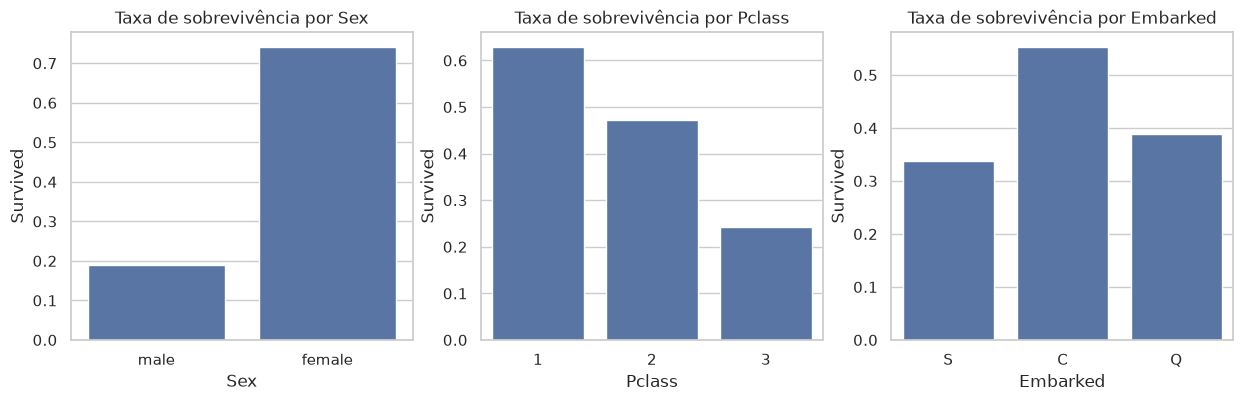

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"], strict=True):
    sns.barplot(data=train, x=col, y=TARGET, ax=ax, errorbar=None)
    ax.set_title(f"Taxa de sobrevivência por {col}")
save_fig(fig, "survival_by_category")

train.pivot_table(index="Sex", columns="Pclass", values=TARGET, aggfunc="mean").round(2)

,taxa,n
AgeBand,,
"(0, 12]",0.580,69
"(12, 18]",0.429,70
"(30, 50]",0.423,241
"(18, 30]",0.356,270
"(50, 80]",0.344,64


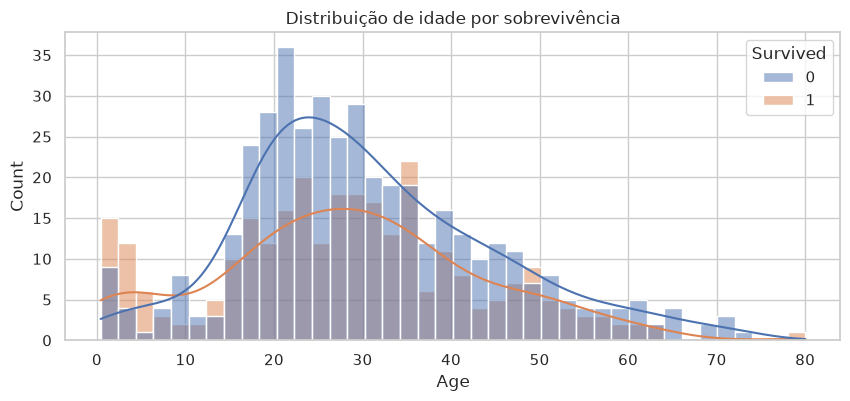

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=train, x="Age", hue=TARGET, bins=40, kde=True, ax=ax)
ax.set_title("Distribuição de idade por sobrevivência")
save_fig(fig, "age_distribution")

age_bands = pd.cut(train["Age"], bins=[0, 12, 18, 30, 50, 80])
survival_table(train.assign(AgeBand=age_bands), "AgeBand")

**Leitura:**
- `Sex` é o preditor mais forte (mulheres ~74% vs homens ~19%).
- `Pclass` interage com `Sex`: mulheres de 1ª/2ª classe quase todas sobrevivem; 3ª classe ~50%.
- Crianças (<12) têm vantagem clara — "mulheres e crianças primeiro".
**Decisão:** manter Sex/Pclass; modelos de árvore capturam a interação sozinhos; para SVM/LogReg, a interação pode precisar ser explícita.